# DenseNet121 ImageNet + CBAM — V08 paired five-seed experiment

Experiment ID: `EXP-DENSENET121-CBAM-TRANSFER-5SEEDS-017`. Historical source: `Notebook/DenseNet121/densenet121_transfer_5seed_014.ipynb` (EXP-DENSENET121-TRANSFER-5SEEDS-014).
This notebook compares **the same fusion/head recipe** with `USE_CBAM=False` and `True` at each of five fixed seeds. Historical results are context, not paired ablation data. CBAM follows [Woo et al. (2018)](https://www.ecva.net/papers/eccv_2018/papers_ECCV/html/Sanghyun_Woo_Convolutional_Block_Attention_ECCV_2018_paper.php).

**Default: SMOKE; no five-seed training.** Validation is the only evaluation split. `RUN_FINAL_TEST=False` and `RUN_HISTORICAL_HOLDOUT=False` are locked. The Runtime cell restores the bundled `scripts/cbam_v08` source in Colab; no repository clone is needed. Install dependencies from its `requirements.txt` if prompted. Set `RUN_MODE='FULL'` explicitly to train. `VIEW_ONLY` reads completed CSVs and plots without training.




## 01 Config — set paths and mode here

In [13]:
EXPERIMENT_ID = 'EXP-DENSENET121-CBAM-TRANSFER-5SEEDS-017'
MODEL_KIND = 'densenet121'
HISTORICAL_EXPERIMENT = 'EXP-DENSENET121-TRANSFER-5SEEDS-014'
SOURCE_NOTEBOOK = 'Notebook/DenseNet121/densenet121_transfer_5seed_014.ipynb'
SOURCE_SHA256 = 'ac048a9637a0517f0452f042e46bb8d4fd6b4136e200b1af7caadb7dbd4668ff'
SOURCE_BUNDLE_SHA256 = '28dd7f84642982156860ab3f53ec7a25522983dc9192414495da1e0793061b7e'
RUN_MODE = 'FULL'  # SMOKE | FULL | VIEW_ONLY
RUN_TRAINING = RUN_MODE == 'FULL'
RUN_BASELINE_PAIR = True
USE_CBAM = True
RUN_FINAL_TEST = False
RUN_HISTORICAL_HOLDOUT = False
SEEDS = [42, 123, 2026, 3407, 7777]
CI_LEVEL = .95
BATCH_SIZE = 16
DATASET_ZIP_PATH = None  # Optional exact V08 ZIP path; FULL discovers the shared-folder shortcut.
OUTPUT_ROOT = None  # Optional output parent; FULL checks shared-folder write access.
DRIVE_RESOURCE_ROOT = None  # Optional mounted path to Cashew_Leaf_model_result shortcut.
FORCE_DRIVE_REMOUNT = False  # Set True once if Colab reused a mount from the wrong account.
REPO_ROOT = None  # Optional existing clone; Colab otherwise uses bundled source.


## 02 Runtime and repository

In [14]:
import os, sys, json, platform, subprocess, importlib.util, base64, hashlib, zlib
from pathlib import Path
if RUN_FINAL_TEST or RUN_HISTORICAL_HOLDOUT:
    raise RuntimeError('Test and historical Holdout are locked in this development notebook')
if RUN_MODE not in ('SMOKE', 'FULL', 'VIEW_ONLY'):
    raise ValueError(RUN_MODE)
use_bundled_runtime = REPO_ROOT is None
if os.environ.get('COLAB_RELEASE_TAG') or 'google.colab' in sys.modules:
    if REPO_ROOT is None: REPO_ROOT = '/content/cbam_v08_runtime'
    if RUN_MODE == 'SMOKE' and OUTPUT_ROOT is None:
        OUTPUT_ROOT = '/content/cbam_v08_smoke'
    required_paths = [p for p in (OUTPUT_ROOT, DATASET_ZIP_PATH, DRIVE_RESOURCE_ROOT) if p]
    needs_drive = RUN_MODE != 'SMOKE' or any(str(p).startswith('/content/drive/') for p in required_paths)
    mydrive = Path('/content/drive/MyDrive')
    if needs_drive and (FORCE_DRIVE_REMOUNT or not mydrive.is_dir()):
        try:
            from google.colab import drive
            drive.mount('/content/drive', force_remount=FORCE_DRIVE_REMOUNT)
        except Exception as exc:
            raise RuntimeError(
                'Google Drive mount failed before any dataset or output access. '
                'Reconnect the Colab runtime and authorize the training account '
                'that owns the MyDrive shortcut, then rerun this cell. A shortcut '
                'cannot repair a drive.mount() credential-propagation error. '
                "For SMOKE set RUN_MODE='SMOKE'."
            ) from exc
    if needs_drive and not mydrive.is_dir():
        raise RuntimeError('Drive mount returned, but /content/drive/MyDrive is unavailable')
    if RUN_MODE != 'SMOKE':
        shared_link = 'https://drive.google.com/drive/folders/1it9ayE473c0lLgxhiNnguqIkKtceI5zf'
        if DRIVE_RESOURCE_ROOT:
            resource = Path(DRIVE_RESOURCE_ROOT)
        else:
            # MyDrive may contain both a real folder and a shortcut with the same name.
            roots = [mydrive / 'Cashew_Leaf_model_result']
            roots += sorted(p for p in mydrive.glob('Cashew_Leaf_model_result*') if p not in roots)
            resource = next((p for p in roots if (p / 'Dataset' / 'CashewData_Split (8).zip').is_file()), roots[0])
        resource_zip = resource / 'Dataset' / 'CashewData_Split (8).zip'
        dataset_shortcut_zip = mydrive / 'Dataset' / 'CashewData_Split (8).zip'
        if RUN_MODE == 'FULL':
            if DATASET_ZIP_PATH is None:
                candidates = (resource_zip, dataset_shortcut_zip)
                DATASET_ZIP_PATH = next((str(p) for p in candidates if p.is_file()), None)
            if DATASET_ZIP_PATH is None or not Path(DATASET_ZIP_PATH).is_file():
                visible = sorted(p.name for p in mydrive.iterdir())[:35]
                raise FileNotFoundError(
                    'V08 ZIP is not readable through the mounted training account. '
                    f'Tried: {resource_zip} and {dataset_shortcut_zip}; '
                    f'DATASET_ZIP_PATH={DATASET_ZIP_PATH!r}. '
                    f'Visible MyDrive entries: {visible}. Open the Colab Files panel '
                    'and set DATASET_ZIP_PATH to the real readable ZIP path. '
                    f'Shared source: {shared_link}'
                )
            print('V08 ZIP on mounted Drive:', DATASET_ZIP_PATH)
        if OUTPUT_ROOT is None:
            shared_output = resource / 'training_results' / 'current_dataset'
            own_output = mydrive / 'cbam_v08_results' / 'current_dataset'
            if RUN_MODE == 'VIEW_ONLY':
                OUTPUT_ROOT = str(next((p for p in (shared_output, own_output) if p.is_dir()), shared_output))
            else:
                # A shortcut can expose the ZIP while denying writes to the owner's folder.
                # Prefer the historical result location only after a real small write succeeds.
                import uuid
                try:
                    if not resource_zip.is_file():
                        raise FileNotFoundError(f'Resource shortcut has no readable V08 ZIP: {resource}')
                    shared_output.mkdir(parents=True, exist_ok=True)
                    probe = shared_output / f'.colab_write_probe_{uuid.uuid4().hex}'
                    try:
                        probe.write_text('ok', encoding='utf-8')
                    finally:
                        probe.unlink(missing_ok=True)
                    OUTPUT_ROOT = str(shared_output)
                except (OSError, PermissionError) as exc:
                    print('Shared results folder is not writable; using training-account MyDrive:', repr(exc))
                    OUTPUT_ROOT = str(own_output)
        if RUN_MODE == 'VIEW_ONLY' and not Path(OUTPUT_ROOT).is_dir():
            raise FileNotFoundError(f'VIEW_ONLY results folder does not exist: {OUTPUT_ROOT}')
        if RUN_MODE == 'FULL':
            try:
                Path(OUTPUT_ROOT).mkdir(parents=True, exist_ok=True)
            except OSError as exc:
                raise RuntimeError(f'Cannot create persistent output folder: {OUTPUT_ROOT}') from exc
        print('Experiment output parent:', OUTPUT_ROOT)
elif Path('/kaggle/input').is_dir():
    if REPO_ROOT is None: REPO_ROOT = str(Path.cwd())
    if OUTPUT_ROOT is None: OUTPUT_ROOT = '/kaggle/working/cbam_results'
    if DATASET_ZIP_PATH is None:
        matches = list(Path('/kaggle/input').rglob('CashewData_Split (8).zip'))
        if len(matches) == 1: DATASET_ZIP_PATH = str(matches[0])
elif REPO_ROOT is None:
    REPO_ROOT = str(Path.cwd())
root = Path(REPO_ROOT).resolve()
bundle_bytes = base64.b64decode('eNrtfdty20iS6K9gNDHHoJuCSepmyYONI0v0tGJs2WGpe3aGYmAgEqTQAgEMAEqiFYrYpxPneeP8yPmF/ZT9ks1LVaEKAC+y3bMzEdsXmwCqsm55q6zMrMctzwvjsPA8J11sHW1d0b8/+1E49oswibeTOFpYqR9mwdg6eXv8wQoe0iALZ0Fc5NYkyawTP78J7q2fO68drnwVX8UX/f7pheVa9m6vbXV7O22r1+ntt62d3c5B2zqAf1pX8cn744sL7/z4Q5+KXm35cXGT+aM4yYOrrbZ1tXUT+FFxs+CHKPAn3iyMg4yfoUdeNs8LfoqTwhtRVzwseLXVwn5stbf86TQLpn4R6AM8li8tGl8G7bStUTJLo6AI2nK8k/Au2M4D+FVOiJXN41yNNJylSVZYo/xO/f4lT6DhSZbMAExxE4XXlvjyCR7FF0e+o4mSL/MCmsiLcJR7o1CWmAV+7OVjeHO4JwumUQKzLwrgg+dHkfroj279aRhPVQF6EXh+7EeLPMxxYj70Lz+fnch5H43mMO9inmf+KEu8SVd/SrNgFOYwfP0lvMNmt9pXsQX/XG1d+5Efj2BZTIBRMvWiJM/5aRzmgZ8HXpF4Ynm9UTKPCw1OQ5EM1srAibJ17Z3eTQmsghhGvTCeBFkAXfZmuQdo7YUzmCj+lvqZPwNsyHLoR+FHAqOu4nEwsTxYcRuXt21lyX3eOuLW7sPihpaZvrWcJA1imN97hBgH9xEgr4uI07ag0WQMawSP82Ky/RqgWz4QlABEwLIQWocVgrac03BU/Ile2JM2IGYQjWPoXu5i84PO0LkNFrndalWrO/QXzM8YarbeGG+xqk3dLwemqAU+JIUcF/6GjtDI6L18fZ/D68cnfkRucOdnIZCxFcaIWNewijhoL0680bU/45nlXy1tqFiT6AyqEUVo3/h7NKapoI68Uq28soDQsaL3iH8+IUnq9cKJBctv2aL+K0uUlpTuELFutZww9yZhFNitSsM0Sh/Q0foMKApcr59lCSzB1dbZ+cnHD5/e9y/7R9Yjw38iFDGqJvfQaWzEiRJ/nNt6T+4UT/EAzzKgetUd4EdjrwgeCrsBT1q1MUIzAx7Z1dbQ+o3Lcwlzyh/EbIlvcu7U5zyNQvmRenW1tXQWgA/OyzlIs+QuiJHkrVmYz/xidLN6MvKBLZpvUx9bQ1rTey4IuFcu8VXJuK+23uA3Z3Y7DjM7eAAW6SW37mU2D0QTRI5YvTKve9hI7iB7BsyLoCLhu3OHw0ByEfWR9EeRnyM2D4a/NjYTl7DXojINRvXMgz7zQARb2YCDyH8UEAdQKojHtuQon5kvTFpN82g0LWZUTqX6Jiqi5Pp+k8fkgBWFmKqMiZcPm5sAWfGa6pjVGg4YxLDFi6FWYmgCom47fpripIxhQiQQVwFjQC7/1a7P7RyUJ1eXFrBwQJJiCK7bKEmsIAIVpwYLBGv+SoigKpBlomopKCFUSzgODDJH3LPVxxbVhsITkNaFLjeNWUKs5Dl3iZeN57M05/n6EqY2zWxbrArQVNt6+VLXWmz1ZTW16nUkotEKSSplrQyx7I148JoQbxntIQqClgcox1wHcKYZL5k1tVUZ830JkPtg4A8WcfGPtqUggzbk4sNA17SG3BP6iD8qH81VGAdR4WNRL03dbqfz0q5X2a430aqAUT2adGWHSmVPdgi+CeD6t6b+TLrV7mg1tusNLO3OuHcj+7NcO5T9w8KiuVWFmzq8WdXt9V1Zh8kSOZFwpGyXnJM+tUpsXcXsclBVA0DWrsYNmJ2u0KJNjbtOzladVzxTD2auAQtfAi9Zsq3zZI12dKa8bZmFGolQq9CyXvJcVNXCJbxdZw4GeZrc/Lsx7+/EuJ/DtKs1M//e4iWvdqBEBsnt05Q2JISmubtXJcuggOF6oGsFJBNcBHGPu26tWzC1WSE7VkdG7KWO23UstKv7wq/CQdj6hdMbsgg0ETxKFLdJFCFjgtfEVbhoPl5WMB/X+QkW8WhWltUqSyypPQe0XF2bSizjNgLFm2Smjv2i6g2ovgkshR9V9iNK2y7NOsBI4kk43XAzgjOZwBR6t2GMEyV2hoFYTNofoq0mj4NirwNbC1z5/r9+2v7cvzjvX+51ti8/H59fvOt/3t4jMt7udF7jKJzDvc4h/rV72G01sjFAvCDOAwDc7XU1yKf984s+wIa3deDdXQZ+0O3gX/uH+8uBh4VXhPFCA/3z2WVDfw8Y5O5ul/7qHbbEjjhP5hkgdAjagBTLsHnvovqhJmhQrs2wYZ0VayyLeaqyXPEB6x6yNbds1+DQUjzJvjB9lD3TdTEhtrnIpKsBws0zaMc5cQYNsQBtEEvIovaG9t1CYfOvI5+Vy9ZQqnLCZkX4J2woYhMojFTGTlAarnAjKH6v2A3aCgZWRqOl9/OF9/b4ov/+7LzvzMaI1WQBYbQuh3a19Vvd1Cf6Xw746gr/exfeBdYkfIBPtL+EEcN/AZpA9dq0r3Ys3SZxtXURBKWN5dUSIoZBovFxOgeycazzxLoMctqw/whb62ReWFKn4P4AY/5Bb4NeOb8kYYyb9G3rMRu84Bovhk9HclTYKH0qWeWL4ZGzO3mitygaofgbq2pTEaL3autw73fWyZk1wNIltxMw2pZ6TWxMvB4ugYbGCBTkBuuyfpCD0bCvgQc1rfrFyVn//PLs3dmJ97n/6ePny3XLTrZt3cwboO2UJ/gTz5gkRVoeKo+2YCu/8bPAKm4CKwchRUZjxot2Ze0RP4rMD+NXQGiMHgTKz0Y30KtRAeu9nafBKJyA0ERTZho41iUAJo48RoqHSQIxCPXzCnDsw0Uxh0LFdqGVQjrOc24XbcIGxjIS6zgbNGLsXx3nVYm1K7Zsf62O2ay5BN+hFs4DlhVY/+qv1W7ANIC8pwkfJ8Rd5jmTnCQOjRUJOnEYeZbjTIzdwvUCvTVrxkLUeewMpFxVLUKLGelXUgOhMWDJkqCwzO+tTquO89DUaqhS5WoG+i8AdNiE9++Oz97/9LnvHZ8fv//zxdnFM7gdrBHMPFrP85KvoODT+ElF/27gLsRWBIuhPq/nMVWeoNZBLk+LDLlyrYTiB2xRb0uomuUgEAASJUxsko1VCTy7adX45efgLgzuoco4vAvHcyRPohOcfVzfbY0CAzR/5qAmQz+RFyyQPEfRHBt1vpJdvT/7cHZ5fHn28Xztir0PZ2FBK5Zr4ohsHjrdg44QAUqVhJ/BWJJZDJOznPqbJBYQ3kKS3N/mflyEE3j2C2CGRHZ0FrENoKEd2FCNgqyAX8WCOddpEF5aE5qbkn+GNeaFpyMWnlLQjMN3bC3H9SqihRDAoEYAm010OkeVDNQv6yKZFDP/wTpeS/HVszDjOCMADhyTMkInh2RuiPwFbDv0s8OPWTgNY0KRv82B3Yao+9z4cRxEiHA4jT699IG0Y5pYxOjzH/90Yk0CH7m8NfPT2iEiFM6TDDbG92jHLSbiPE97LQreBpmf17469FqW4W7zuc7/pi/OvAijHLT5KcwfsBx66eWg9AMCfMHJtcXkwKSJAzNhnr2K2Th+wqM8luOyxeS8x7+kEZeOx8SZsg0LPgH1LhjPibvhMV6YuN19NBHe3vvZNNdtv/k8xVMqR1VXhbQyANGpAAT2DRhnV95qlYB9NNb7vdWtmJZrxxx0zmxUms1B3lwHVprkITIkcTAox349D6OxGHgYp/PCAwUhDfRxCmzJqd+qxGC7OzS6rIoBPZwDwa7vKislgJbAEoF5Wbdxch8r5Bzj9o5PR6sTavSosOWjVuwmHAP7g+9AZ3a3Xan26lXjBFebmYxw7yOw5hQ3bzbDxf0RzKUv7A1ZEM3JRAEKFTyShjX2oHa955NRrwrS6FodSM8EInCOl01fMH1RFSnDxijVF9fAX/8OD7AKMQ0ByTsGCd3wYafi4sz19BM8mM1wNp+Z1WCGV9eKkmlIZm85BbacXhv60ELNuf5FNKXDERyPmqZB2/AzD6ezJBzb3Eirbdnb0D7/Z0xty5giPFVfOjOiIf6AxjyEY06qqKSDnAbSGEGAGwA+vnwpF1Ar3BLuIToq4ia+CUWfvjOPvGDm/2weCU3BnHp5+CVwD76RPWqwBEFrbxrYol4eWKJFZyiV97+zenhAvAG/1GtVeSWJ92Q8buBASXxXEvIJPPVOFZ/RQKJ5ayxEO+63kE0YvEOg7/O5suqG4AX2S505HwF3rlDh35d1IBHeBkEKXDzXrR0bc5FVAAQ5qSlAPoBarV/YyFHasoWWgvWPTfwawijC1959b6JHufstytD3JP7n6kbP4hg6/4eCNYVwTTNSM3brbNJs7ysIl7vSSIxNfVhdcCPK3gTp9SYNxUSi/N9d4LWbnAU2oRfYEYltn3fXea3viN5lyRfQDdEY85ezT5Y/HwvL1iVZu7QdJp46IJGw0eZ6UaCaCvuhOLgLMpgC2LUFY7UxWu5EKR5ugBrhm3r+EqboxrVuS6W8LzUPVBzh8eeTH89+7nsXPx739vYtNMMc7J3sHfZev+2929/d6R2fHB92um9Puvuvd7r9w+67w+Pj3benxycn3X7v3bu9nf2DvZ3Tg+7p8X7npLt70D/AYcAutX9y2T/loxDakNORwuHOYdt63dmBPw72QL3qHKCzbLdTO+6QXlmWvdN5DUIIWUZvf7dt7fTgcae7W68AE1tQjW6PgEK57g7+2sNfe/t4QnH24fgPfa//r5f98wu0PHD/nF/SKZ+6wa9A/kxj+es+uE7Fz+sZ/HoqnQeBRGDe2PdRoO4NABWr5IjPLc1XkjyZ2I8SEPi6wYcJt86jm3l8i/Yc8n+M/Nn12D+yJnQyZXet3//e6nWABK4Ra6oefDfOPB2jPyMBMXf6N85N8DAOpzBXtuYDCagYThYemWXvAmM4+Fs6QtJ7fi38DPFNoysha0nv4PV5UrxL5vGYlSUNBHcDVXptEhV0/uqQKd1uoSJm4mqtLdNRT1KmQGzNWY8Bl856dMZMh3ZkDDqyBp0hiOwIlkkjFuFWRRZsWBaJ4E/aygpSdP4SpjhuHg8u7pdJzdtrdh2Qve/LxAnjSUJ+etV1pKNnLIgTjCc/Ta6aeAQVxvPK4XiKR9Vy1QQQ7BtuDFsOfa21FRFeZngKAZO9iyoxPeJ0kJ8ku72fAkP0LtiBsizTHRI6wIh4Ojd0p5zHeAg7KgJxJADqMvcW1qnS7bp3JfRZYCX2AJTVlpPPJ5PwwSFLMiCN6FKV6jfsXJzE23Qi/3V942711MRoyPT82SGlCxqWQOst8rwP5HIMB1p7gGPj4MGWlVtD6wfY1yhS8+OFXcxTQFkBJB8SDkgkh+fS8US+bG1AgKwqCgLTSJDflGOQkh7PdGimPWYJyM6ZXNvSUyTHd/yLXOtZPONLatJgzsFDgU5+HskfdOcTfHcMAMOYxHOptapXkmz0UmgsSCLgjK1acXEqC3OL8SG0y2hbTWe0wqNcb+lVI1X9iizlG/kCSJ0mkreViG9Lwb05qypAow9wYmxzZmq9qyxBxeGdwSCnzIKITk28IrEbVnrNVn4e5/4kINGBk91E2OuZsujMppihTk6iPFgOjeE8G2h9jqh0bpO7kniF536gXwMQ2g8B7WvTT++Omr3qGEsn7J/NdQg/2R2jLeHLqBCp7iTz4mi5m55QVfMb3KYuL8bfYdOeLrCbyfUvtmwW4FdPOJKiZAwzPw4nAbnGoy8GSXW5jmghIim/GXI3oNBHjK+iOrQjwJNvEiPAAv0FmoZoS1AahJaEmiD6AY+L/Guy6Uq0Ztfftvi/dKqkcmz6xW4H8XwWYAiRocRUmEaKJWG7ABJG+UXx4F9ZTHSofhKWNygnaVXcbiZqaVzSRTEvAJdbDSjLw5bF6KmhlJoUWTB1dPKn2XT83ENj3IOKFVJMDTpCgi6fz+xS2OEEDIk6BqIXJG/skHXAEMeZ+fE0sPdapBoRq63WXyMeWdl8UqjIMk0JyapoXIYMJU4LSWhXSrJjtjwSRRdtgM5ml+6+kn4529EQhnPKgBzcN3q8nfTyKBwFuW0C16ZTwtcGTTDHOWyBAElAdJUzzp0SLuNohacCXuBDxxDf2KypsTIaHm2UhQBndNAae+D+h4nD5diT0uZX5M03UeKzrU6Z3B1knSkQqQerMOMTZvedD2xYw7UHB/f/fFZg46FU2+I/d5rPFUY+YAO2jF1AqQVzbT+0LbvXg/0r/NGiEIubZOxebV2HeDzsZ7DebaxMTsI7vZYYo4EDMJloOOQRAqXPZx6eEUdREHlomMlduYTHP11+vPzpvN9yaLntctFByKMrHb6sFRYWjwB9Mlm1WRUfmwXogYczRlyOXARKV7W10aLSXBHOgg2sHjDWdIGCI05F6fw2gmkD7YtdHGQtWzn65aMkCxDfKwGa4oPgsTJ6UsRIehP66uWw7QRwbXJDoqN8D9AjC2EZpQtva41lRaigPJmBTR6j5G/ojZsImWRWOi/alhEu1hYHXwIrBcpzUSkz+Kmlf9pYS0iz5BrtnzF6XZCtgXvYasG2j4tQz20qWDISg0rIM5rCVHA5HdiwT9g1H6VCKaE8nXFqxLu+gWZHaYwS6HQ6sFe3G9q1tmW/WiDN7D2xpadmJOGiB7nL7TsCoW25QndBdp3kgdvRhAYthcHYsT7+uY1/OngAQYcFq84dqE6cghqW2vDQagL3isChWFoFDsfCsPzczzJ/gfBge1Ms0sAlTiIKLsxSEvm4YBgXFbkIYEks4sOCBKH4hadhuzsd2gNAIYfPibokBPdWK0W6zw3WerVE3qUc70TgQXcsZ1R+B5ppW5O2JUiUyq4kYnvRJqiS6FyJgm3rS5AlHvo/YW210iM8VaoS/lIoyphFAQE80QAvxgqDDjB8EBTDcoLxoEGUpfVt0awedjprps90tKVDRtxPoZIZPPjkMwRAVDdY4VSzOu7diEOOOKVmZbn/Zdk847CyKlpN8lSQ30gRQrNwxQZb6MuuUIYVw3INxsXiXTvtE+yX8bLCpuXkYiBdjWGLGksYuVZVPxw0IvgFhNShI0ZsRI/mF1+z6tdJV3yZqC+GOwJJAVFEPnJvkus6luiVl0UyubBMbe1r4UcuLOrqmqjjY0XgGWbZZqbpNr/W6pnZBuTsAJXDzNSyDsippc8ljOYMBArWrlFYy4GBAyuTXrjkmDMjKsLWyy9YTqsmCwKtdVaBFt3X4HbrcCuFelxI1/Q4CUdD2R0qq4k83ETJMFHaTNoYQq40pzLCWQY0qN0LakOu0g4GYTWgpgAx4BGSuZriMVhAySFTRMNXfE0FqqZD6ekplxNQeBAyGCyPOnOSob+ue50kkY2tIMsQ36tnMSsYgvXy5SOH0V97j6Onq60js8VfRPzyL9Di8m3sU6vuPqtty1hatYx+2Y2B5XLa+TW5TY3aVh27cYxWBYnr4y45BlcQAoiwQ/zmD8snqGlgK6diaOzMOc5eqIdyD//8lBywV6oG8C/LzAFFjeQcjOuN6TmekaJDhIVpltByUOx+7pVI691nSTytZQv4hhGLLB9rSXI1FVZMr2tIcgMq3AjrUckg+vyNok/aoFWhWf/iWs7hcIPkK9UlHpC3YjknbBkrp0IEMKrxirwHangY3/e1SVtIuIAK498FBexYNKSoKmw6kY9mMIAZqiy/G+Mz6PvoUg4SBj3XlX+6Bm1FphLNTV1LDSBKoV8EBqS4uIVf6pItNvSijth3c0yhCsHTN9/oUr59CS9hk3lhpdE8t1Lgw6C3pag8b0+zcCxczt9wmE6YUySAiBQgPnMdBaabwbe5WetVvJv5tdwOay7kamcMPZKfswAQcTwfhWj5KBbK1osmFszmAnPx6XP/on9Jvgi3/nQKlPnqFTXzCidH+0nzBPp7XoQRTIZHk9Hd93q9XdZq4qB41eX0XN/R9ekyuQ3iC7SIbeoARRtR/CtJXbYdfZO/kwTHv5MUj9DLFpb46xTY6yZ/Hf4wOGprwI8U7LZ1NPxu/joEW3nbiD7ja+h1+TZJtTM88kfy2ETAGsQcdDlcEWJluC9hfGnzaWMIjCqjSZZdk6hla/IVXc1V6QZnc+2jW6K4Q91An+vw8gzx60QVY2spd8iuMX54yfY6ghtgALruwckogczP4y351ZawAyqOcQ04eY0RLK7WN0e+bRgU2jOA0kZBnidqhHTiQwe9sqbDPE94fHaP+ODX7h6iz8xhr27FNpJCXW29ff/x5I/9U+/tn72Ljz99PukfcfwLD5r3qcFDmmDyhMPX1gMCFRgnpFLZSzVY4TYpZt45w0dbmU/R8CptF9pEKa/3zL/3sum11/F6e3sK5oMCd6FiWOyBoN/PFCj0LgpTGNJNkoVfcGsdyQQopJlZP1iGl5JR9XPC8Um209k16/SW1vlLksxse9vpADLAH+R1rj3oQHaWArkE2Z9Hsu0drLxj1t1dWvcEBpmhsdpBFyu9zh6mghHTyYfnaPP1/PkUo+VlZHPpwoqgf2td+vltDe3IWOynaRSij8e8SNDMjmxpYV0vuMoEmLrYFL2RsIqbkE4JgQDfzWPaLfkRW+oYqcL4DrDICgtl/kgwOpzrCwRzFdnYSwjDfpBK1YgiQcT8vIvIV9cWU5CI8CcgX8zGALBx9JoYwI1kyxYctjy+G93QaZ1WsCfPDgRkKsQgc5pjBCzgaGA8EvCqe59F5ILdBWSj/w9R3TBgYg2vu/uAwf8tW3Sm5H6SiR7pGUS0lsi9VwAU4s8uCxh9kwFeqnt/iJJrPzq+A2qbBp9ATwEVqHdqm93z00aQoMQEY8MpfgQ7nhh3PbI3sAai4bmI7LEHIzRnGt2RKqaKGzHiZfZWMRBpZOGqRmyjcBBF+Uz6AogaZiraG5qALCl+ikPQ0Ge2wUE68E+rZdMwW5p9XXGnDyTppBc7d6HsmVJ6KjNgCgmHaJaCB12L7Oim2slHEaXwUM6MKCkLPDiT30h1mQb62XhBlnczLGJdw6BuazV762qiidsI2cCj+HpJ7z6AjWDN14zl1DHI2QzZhpRUJJaUGB0DllNENailQfAlUHNY8cGomWJ5PnjOPvdPzj712YeU3lNKDniIMvzRDbZ3Ub0J0mR0Q35Lr5+MTaGo1TNq7QXb+2atbo+e/SyidQ95DwUll2U6utqaActW4A6wOiiSs3nqlVB3np6MbYdKK8Ibj++wQ/he+wFGzpJt2yDdJUY+GFwR5ArwGrvrwB4OhL+jEQ4Pz8sCTqoETAOhGHQh4JwD0dJegIQqJQMZOLuvUTDv7u3jn539oZFlBI04sGsfOL3e4cuXsFrwY1f+2IMfwzIeRbORVrpWDhB799DaTAcWNACA5I6n9E9p1Hw30K1+XUVqEyXqtVG+QW9yMJfNepClimOWf75688AHTRIFH+p6OU8KqTojdiVgYXNOVAXQRtF8jGbolM82y7UTfxu2e6WUu5XFSVmg8hZnM77/oGtCD7UzVtS33p5bZSpmIAgKbZ9wkAP8uk6KG2bgubNKh3hYojo8tGrkulpLmPnxHBQuoSY0VD/NkhT0QxuoUV9YVVQdkVflvhk5x1H0ZBNaqw8wyF9FH3gwOVGTKiBO+f955DY7pS3YKVWV5+WoiGx6aYDiN7gAZt41jNTb88hqG7MEx7NWKBJLa4ziFm9RRTKYeetXUCqYwC3qF+9Mbvy7wCrHIuAZjqTC5zrShkyz1TBTdGasDXHV8FrP7DQQPfUYYC8Esf8aetBOTQ9aptHsLtdoRIinXpqAlJoOqFv7G+hXUGzP7M1Op7k3r5/Vm91abw4MDUvmg/unUq8MfpSkuTNB0Q4FyqBYa1v7jGQAyIZHo9x9zRY26HZ2HAoA63b3nYODQ7omwdl/PWxgvv+j/fxDaT+r1RzQvM8Rtf9hdBxDUVvmU/Y/Csw/oQIjnfIpPcgm8mkT3AHoGykCS+Qpo39JI40y9Z9OTu7U5OR+c2d6z+pMt1lMkqBU17joZ58XoOBgtqlgdJsmYVxso8GmzJkpQ/PIScDnQFY661Se9ZvHVuteyiqumuWoFgZehqdQiFopQRvzbB2tifHgOuMw07N/ite5jAXTiq1IAiqnwjXA0i0Ljwia1OmnMk8eDFE2kAcRxxm61iAtQ0OoVjYFRgdo/hK1bgr7UPG+SglPq4FXWg9aujvWGE/q1VpigmZB0SlHn4kicrpHPhSuFTIBpkuiPqHLrDiJ0O0blOLDFcF1Yv7IWkZeA8ksFZn1XFX27JN32n/3/hgjIBsD8TimRsxnRSH/MmHvATsFGVePVDH8Xcw1vNr6dHzyR4yt+XB8fvauf3H59b4uyy7cuRf+HnX3C9tudPmQQZr4mxIbmFe1rJuNWiOrg3faKk4cNYRKyJps166jvlhWKBnMnhzZZ8OPQwAWJfUsrPok+vkoDKs+HKIO8y+8o8rIEsGpPS3iISC355QzmC/iqSQhxdtrSEDykdmqAAoZF7eWn838AruEiQjSBf7C5U+jYkVYhXlLV9sMatj4yq6r+Ofjz2fH55fitq2VN6FoV0yhW489CadtiwPzyH+tIQ8BoQZRhUieSlfHYOmy7HPjJTH/d4ESH3dTqJhp77Ff6MQgwofT0O3ug9Z2fZ08gOqEJ2uoS2Pl0o89KgDXAKu151GU5DS+emyXNgnsFeTxyMjvSV7Jkuvz0laZL1FNDct9D82f/0BHj9SL+TUhJupMEUVpEqwW+nRNKRDM3hfBEeUn5dcuAGH0QBGBFll43bGNLzUvVx+jm+QFAyIOkczsFBKI96VgBTWKahTiL2394pzSzVHiUOsb7sIRlyisvxMH40AaEtNXAnQpyIm8bQqZJl849dNKcB5bfM0pW0U5I7U9x6UUZTp+swn/wYEeY4ZcdNWfzKMIdf5fkCfBMxBRDhwuQE+B13jY/xqXSnoYw7JH6Y3vOgetGlDq+rWf2b+0K+23LdhfZC4VkG5yJDNHfkrosb/iRo1RAlsDjGOLgO9ipZmfgdCleq91yc9RdA/ANm5zmw/M28ga3grWwCyBTBeGEBEVixCwj+ImCb+ejqw9mXGaUuL+x/+3HuUqyJwhZo4EAITnzBxNcrVFF/WJ6ertmQTZzIc0EhWXwdQpVOC9SacLI1zxmdeG1Kb+K68RaaaAtZgvmEmVlSjOcdC2dktWoVDXuB9J8ARX3uDA0o7mUK0Q1PUfbnAkiBsSq6aZT+sU3av4H61gFY1ruCib5RIGAKCi2NbJU91b0Ui0JarUaUG2gsnhxQAL6+RMbxCdwh5kuQu6tE6ihbsQDJMw3BUJTf/z//67yh2sA4qCKUY5Pw9dm24eWL0taZRBg9q1mcfiybJ/18I33U6n4nJvXqz5AZ+sd129/FB0Ws+N3Hhvg7ydgTKoU26mf7jOilvD0NeWrK1AUjKLlCar8zLyv4mRmP2AVuWqqgtQRGbx+oQY3eZM5HaattY0p0/T8ubUQpjNqVltam7Zwqy87PS09yOHMsHEowMMkKW4n0dbhkaBJPvdFF5VRZp1fA0tL3t6JM9zlBQZtRHlG2ViMKXCsOHCpxU3K/633K5YvUCSEiAsu2GxPkyZrEGEOUhAg3BIoQV8WS0pb7jaX6mr4dqGmM3/F9C4nD2EBoJ+E2Xroa5Q7e6t0KgelmhUG2l/K3SrBlVsRwo1hYugfKLW2WGFUzOYmxpXGfOqISGSOhv83V7HlFYLKa0+03JIJiiF1Kcg2+bF5+U6ssaJMN6gGKzKP1Ns1eSVjpUihHcZwTbuana0rUz3dYVwcXNS3iNXbkY4Ek+/4lm/Jhm5b+tbNyq4xBhmHdyFfFKiUrc0R3k9g1+s5Bmb8o3/Nt6xjBUs4SPIGLQdXZ0pPIsxqJUpc9DoBNl6oy1YpQht+FZwAtwlS0qrsJ7uXlviAzGHso21HCBZxQGW7rHWUfz+3qpdlrjzjl+0ntQmK/fRemVdnFb3VlidmQYQ1u+qXwUDmCRxYWwNV7KCelx/12QJ5o27kgp1ol3GNFC6a0yjB1rPQdV0CduJtiKhkiiJmFrf6bZucbFHoN8pblAwHXo1HXiZ9Kvu2J7I+8kWfKD2SH8+fQuxqj4OCNZwU3nPJ1zC49TibBIlrO6wIZoRVESdWZeTXtPm+RLFVtOMkFaHiz4gcLCMy9jj2skth48ZNKoT0Vz+t9YFwe1haiPoPwfiXWOKJ/7Q1Q6zHOuPQZBiiWXAMIMhwMgDTPVTYEKbOVqAk3usFGKi2CyJE/QTx9thaLLxNpZY+unVbmGaTHJKt2cuj+HnxbpEpxkAzu4AI5rvBuJwkHS1HyRkokqcVTFxS6YJmAKSIipPwox3Z95gbcBYwSPZ4CTZpGZ+6jl7kldOhKeDGKMgilpuv1V9m9BOzxOM8YnG/Jxu4k4+LxakPW1vl11d0vEVgOSI6Ea1teMhc8edtJdoK/6DhfNTs7Ro3TySL+7DcXGjLDBVBVqXG8QumdVZ//lv/88qp6s5KyFQaNUnsQH8g5QrfUJvHgjQEV89xNTWWjb6qujRbaPAUei8tCaGJniygGlIAz3hCDIdj+rk3qNg8U+GSBLDkuyfzMFslquMsJK70Cao7fIEWD/XWNeXWg+eI/Zef4vYo0w5aJZO/DGGY2+mRq6K1G6OzK7LCKpYkREY5Q09eoU9Epc3wLsVWZTalPOmUYTo0sOBCniSIzOAjWZ+Ct17i7rlEqwzqq+mkBeZf/9CowWxk3uBj7Fw7wzGL542bWlD9e81rH0jTawAvVgJuhGaWKhmEqsgAsg5b4+M+t+buuTKLSGvpf1QrRumVM3iFzyQPpwL0yq6LXgipyg6Se0qrYKPc3+ChRXHwHfanavhA14oxZfI0m77HhmbyF6MB8XodAK76zs/jIwwfqIJPJT9dPZensRSYHJp3dU6ZRh62yLJsfyodGpTkZUTvFSTreifS9LbbK55Ui6PyuWUNU2TyAVNK5yURt0gyT5d8kiNQDmY3tS+DRYuJ9G3siN5hDKoJqXAFC93IISDyrnwUma6qxsedrU9hDQ8IBFrVgdnEvmwItSxwdFrI0moON8uVwSTwCX39WQbw8ZUyJV8/EYSZAmxrNdaf6eRSISs42k1HzKtPeGbo241oAUNZ0e1TbJgouFMOgmj59wf3q457aPxcIr1q/gR5+NFmWjkxRB46P/5d4vflwlH8L39qA7KBi/KZX4Bc+70Jk9kzaptR5XCFObQO1Bojb2mTwJHreMANzTaUg6PltRddkwD6jPOtWIiGmNpZjzk661uEaqmlNTdzYT7iYjMLW9lHIf+NE44yAceNQ8UShGKd1jDPg1Z4XaUjFRkAeYVgIWrsZ2lDuykHEBvVXZFzARBjqy25vdBcLiPeSUAlmtJ11GswQ/SeZfS27UtrzF1pYir9VOEKhuwuc7gaHe4xCN4hPRHTcmbdcwbmxBgyyGfGUl5eSqryDt2zCo6NK5fAfAc7mKYNbXEP7vGrVootkG2h0Pew4xuMOlPhxKjvdG/GnSmIcJj+HSk7k9sCl4hGF2CIWg6T7GNI/qvM1QKEsz3zF9WtWz+auuifntoeWnoBmRk0oWnIbmio632ViUUwvAxRaWMrh3m7BZog/ApOW7FDSspE9+kwALQHVq94Ntmm32rll7OY5JNPaeOdPkahemifOLctw1+XhWXahX9II97qYtONSoC9OUlX4qJo2fNQaBc0oisUMlu47sQ+CGGEdiVCJJHYInkRCynzZE/ODNMuihuktgsQK88FMjI7Zou/JGzifWgq54s7HniRjSf2uQh6F+roMoZl8Up30sFIC0ploAJWwWNVwsT2uCPKhR4eRsWHi8hFhKZjFdB1FYYamh+fasqTdM5lh48kAAlrkESjC+6Q782tON56c0iR+ORhyZpzPJ9tfWHTz+hr+yKGfcoKkfMe77IBUBk8xyvg1dQNKzZDC9g9rSDl6MSxyrfnCkFWHhpEoUjYJg0ihrA0Xzse5jAFV32xQgQapI7Ah2xU3hR7E+nx97PZxdnb9/3vdP+z2cn/QsY5JPgDXSBLGJu7sBOFjhDOVbX7Tm9rtO5iqmfrrvjdPecrnjcBkRx3Y6z08MShCJYYdfZv4pp/V2363QPsDyv/DYtN749xJflYhLgrtO7itMwona7PWcHoUIP81lyi96quelherGIi5sAWB1n5SbLYv4GLSOgz0FnrjEurLxuDO+TyfBO3IKsk1HRcCXzTHd8f2ZSbsJ3cYm8gPdtlz2vi29b64zallfbs2dqg5Nryb+A+yu+tYrtwbau4stFBz+YWnnQddpWD/7fgf934f89Rxq685WnUz5FlVg56Pux2M/ssXs9+taz52guj6DalAOvGNvymHo8TiZut2XCqtSsODTtWD9YhZOmE9s5xLvYdslVTHk1khUl/xuo6XsVsMYY8H6jl6CZqHpowVhRvDukorBq81xt287OTz5++PS+f9mX2qWoqy2dTbkYcSNl+JZhut7mLz+gbac81iMzoxBq2cLYd5VtPO72jqzuU9t67PZ28JcMhn0YBWmh7Y+M+nm+ImS2Fi00jzUvuBzzIgNo7TaQ5hDFA9hc4uV3LS2QrClOrZazgKGsDlmrBp3l1Xoi9qwstypnjYCh6aq0t5AHLeWtE3r+ebzElVWQuYgy40sLaNjGyNXGE6r8IfPHITCzS8yGRDvPAn5Vg8tlBqDmPPMNV+agbbV+NS0Kur/NgZfKa6K1WlPoCFWB5p2p6JWNcNpiA1SLK9PVYsZ2BstJ1RFd5QzstUpGMMG4PNkDuZVoOejdVweIb6doOULLAOV/q8KZVkDQck1xqWhEDSDjhdrBYbF7h+wWWI0sHasHy+smJIxzGSAX9rPFaYhWnCRbiDWcpXW7CFmr4Au7/edS7NGeWIb5VK4UILd9/VZBcWMM3b6jkFfk9MO3IsiYvfzR+kEvqhhScleYMmavGmap/V1bNVX74BdJ5GIceu36M8kYjyjg5+JCxNmMkjTglxd/Pr/8sX95dmL9dH52aV32Ly6NeE6hFJEaQMofVCnmmJF0m51ySsc+NvKfneal6zWn5hcvGEUsic0yjIpj0XlswFefDPEpZvA2jMemKeLjZIInSRwuU8Bq4+6OdJo3GHpOCBOMZdrA1M8wWN2/95FyQbeMOTpNbM/qhggl0c1Ye0F8enaj8pVIpfUMcR9OLBwZC60SgG59ru/gqhkzliWUfCuDl8lOsSQuWr+8p7LqmF6S2TUedOATJpSkO25uwjHMAOyLZ273sCecUWcB7JOLgN4e7OsWsGcnv9Sids0kl7VEmCrxnmvIlzNEUFhxIo5n5cUUxD6nkN7GlVXsoK0vAddx9NwCuzAzHB6kJRItfzbnxVBtP6KdlrGOtmgVPCzzPAEOlgW0l08DxK3hV3daBtprLoDEW6biihAhXoFQfdD7vSyeImIrcYs59vdADSRfCA3pMAIP595unvt0VS4FvZxa+5DM+7rikLblyLS4/dS8XEncWYAG8oYEBGVuDQXAI3UEU1XQMZDNibFL8i0Xa8lRO53CNbQll2xlW6vFhTEZlG5DFxpiqHUxISapKVi+W9H8V6a2qdz8kzp4DUpuV1e+OSsHsbIAUCZYqlGxTdW0c4qOcU1Nxek2qjdczFBrNlb5nqfuPU/V+3o1T9+SKR0uLzU4moLvpa99F11tBbb1KouKV0IsR7cWLTRR3m9Myvv1tEIe2rPVwrVKIQbvQidlcpPn6IiM01IrXEM0deLnfuEsB/HYGaENCbSTnE2j36BGfvh42n9vXXz4+Md+gyKJq0YmUfhbJPUXqppiJgTv/CProv1Tbsq4lhc/vv94fIof2dxmWG0McxbrqlahAmZwh5whkU7QOqjmSwb/sVkLc+6jny5WFU3XDFubWqtWWoia7DdaJkrtji1lmaldxiVOanWyfhDkvPoOKLyPWijlpLqzb5Uio1j4WD5o7eCNvfUM7WQwid2YPZLFbRMP8pYjrkjiD/oY+/ESZ7R87IrvVhlBZ74ia5O7GgqhqmsagdQ9VD4OqtI/YU0ba1/QFGaawJA3z3NVRDd0xdY2yEs0do01K1fcMqmoMkf4RxuHnI+N4eL7bW6sYYDaJGDBH0TBctDlkHnWyepHU1+bkDLNSGmvUtGf1wuPU2ORuVQ86clzgqJWmG8+hQ9GHYviBlaUrjmCNWCq2GCqJC3CvJ6rXN3oEpvToQQmLCk3otX7MXTTod5NvJF826r20binnMNc5aWWkm/ozObyPtlm70HRX9hexkHmWO/mUVRymhC7jQpgiD1XmVKueRRAygEIwFtMJpV9XaoZ40LMmV6Kb8f8Jvv5isQ1G2aI42LlraCyhLzaskRNIR2FviD2L1HWfIcly2JRxU5SGKuWfko9587x2J/9yaZDE1gOvu8MgbIAgi3UyF+gpDQT3ePdbGKPmeBu1LlI/SwPTqD2NMnwvOsExQpIjAxVdrq+QXRT6Hz6fXKcuMAdCO1A3AhTAymjIaVVtvRZNw7T8iJI+e614CEYzWmvC4rwLyHelqEpGHrIOfqFofTP7dJ7nK6kCtNA2jR0s4sqj75U3G31ivddJwoO3cJcgsUb8BIQM+QYjD4V7GzfNvUol9I4Ubw56FMeOrhTIjmRYoNeCh2hfN8yU48ZnboMshne1R58jM/9c1um6gHuVc86Rc4PNHb90g4FSkTtVFvoI5SLIklT3Hc1jtEcWsV+IZp3ueVBvVvVE1NgeQXeREmTIzfo5VrVDEnajcorSokcSZWM3o1TQp4AsLKoyttUsm3NY0w+70VZ1QmMb5JRg8MEXcPapd8cYfD7slilG8Ojplu6xUUzKd7VyhDwNg30cFsGpmo6SqaYign3/1x/e3lVhIv3hnbbZRn1cVVFUgyqK8jXx8sqMnPZkPzn6epZGNV2QwHUMOwuFEOODnwut+lHGsJ7ORzdTrAWe98LDvgZSORCrGlmy9VttbSUvQ2Z176OYj4TmPefP8afImjWnz+faiY+buJch05iqwRU6+YQYNEMug0zamoHqpemBZpMtrxfqWYL5WyXdLmvvOQXxyBuw8XfteuYVVKd72Jl/n7WwpqyaRqkq80bxsWmxKjKp7r0+NUSZEqVtJ5tZMV91BuEwUET+qVrVELmx1L3rVGyptzYHOEuKL+hQxy6gg131Lm9HhTdBE8Zvxo8kVs1eb8c/Irr4TZto5S30Ix+j52RHY9njiL5REODF1IFZT3rxfCJ5Isj5AvluTP8guVsDXhakHmRLo8pxzL9q1guUUAuHpS5umqIoCvrlV32ZHo1boLTqmmaRaPbsXGlFIUFyAxpIgwF9Cs6D5KXRR9ZjzxhZlBE9Va9r7gOfSObu8lWqvfMNIpsLtMU7bnh3enLYxVX2On0HKg8QchSy0FxPtKBwjAZRqYJX1i4TfGTa6/CRQRmpmVrWgMt6JLSTOrNrwxvNZC+MWt9ue8gy57opb1idDJRa31YOik37XtMPUrugUyPfZoQyd9IrdMH3sT5lL3UKLgyuKJ+mSsRRjReFsgbltpEJboAKjWpd41UHMxSIFmNlmlBRLeBgvUB1IObGoKOH2+PVMa3wa0Iv6T4EOgWb/xvxdOgQ2nZbtngLIJUn2qXHgNtVi4aMhcEIG6yHs3jx0yloQrR9AvFs97gGc+czsGKxErugowyUTrWWZynwNjZEZlihy3OIk3XgtWIQ/nWT8LCNlQbKZpw7+8KVaeSyI5UXreuHrdLtcrV95wwL+Vuk/aZbcy1e42Xb3dbjuhSxUOnjqN/r1uIy9DktvVSdENcSDzc4EbitffsCpADGYg+bAwjrCY4fVS9OqLUNF26DvtWBiTd4eXQjMdtI67Ygfoz6PrTUw0LDAoxVuG31kUyz0bBNpIg4AOmRNZ0DlYiAEuO0HRn8RkWBdSqDFLYk5PzcxlJzjZz4awsNSShEE+6Xj6Cna6Mzqhb3Hm7EY8RN42kJaulm6riPVtfWi+PGkRBU3u6BPXvFdmJQDdb7SUEOejJSSZdNEGLybH13QZ5jE5xmwowxW0KmBLRZ+c8V6QBQwTG41lvHN7xleSdVsPsqA2cSKQCeya7iiADfcsGCLsixhz+2RY3mXfLc/PfVO0QnCbAkYqGOh3OKRELdKHsX2vQG8oom2euI8JbuowrtB+soat1lYWuLq9IHGx2SqnaDQeKKuKO6jUJB+O4kUqpHewGTmhUYbMjR3WWXwuFAkk4OOoOqydPTZ5ryw8jlyKK6eG20WnmugtllX3dcDSjgKSpmTO5DDTVDozkvk0ap6tBcms3/CrFkzQfGHqbvidGMU0bFFAyd3Utk20FFMZlqWChWviedpa9PrZP31cLDVpLoSK3oPMUac0294cu0gFTgyfp323iElhiFZMgCCS/XLQZY+WqQNwEDJt+VThueGStrEsysXL1Lmsr6KPnPqLpOm8dVbLL5ENNNJdnQixe9MsPJMZ6eQAK4Th3G3ZhnLMNd2lt3QEhA00DvuONsIUfufI8Ayp59DE3KEcvLz0kaB4xPQH6m4RfAvtekcx6Lw0deG0D7ta33n/3S+7Xm2OaG3mUZoojQYGaYeJIUaeegrPB/nAkiWKJeeJpszFUTQpbT/8FIQKQVQ==')
if hashlib.sha256(bundle_bytes).hexdigest() != SOURCE_BUNDLE_SHA256:
    raise RuntimeError('Embedded source checksum mismatch; reopen the notebook')
bundle_files = json.loads(zlib.decompress(bundle_bytes).decode('utf-8'))
source_dir = root / 'scripts' / 'cbam_v08'
if use_bundled_runtime:
    source_dir.mkdir(parents=True, exist_ok=True)
    for name, content in bundle_files.items():
        target = source_dir / name
        if not target.is_file() or target.read_text(encoding='utf-8') != content:
            target.write_text(content, encoding='utf-8')
elif any(not (source_dir / name).is_file() for name in bundle_files):
    raise RuntimeError(f'Incomplete cbam_v08 source at {source_dir}; set REPO_ROOT=None to restore the bundled source')
sys.path.insert(0, str(root))
missing = [m for m in ('tensorflow', 'keras_hub', 'numpy', 'scipy', 'sklearn', 'matplotlib')
           if importlib.util.find_spec(m) is None]
if missing:
    raise RuntimeError(f'Install notebook dependencies before continuing: {missing}; see scripts/cbam_v08/requirements.txt')
if OUTPUT_ROOT is None: OUTPUT_ROOT = str(root / 'training_results' / 'current_dataset')
OUT = Path(OUTPUT_ROOT) / EXPERIMENT_ID
from scripts.cbam_v08 import CLASS_NAMES
from scripts.cbam_v08.reproducibility import environment
print(json.dumps(environment(), indent=2))
print('Repository:', root, 'Output:', OUT)


V08 ZIP on mounted Drive: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (8).zip
Experiment output parent: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset
{
  "os": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "keras_hub": "0.26.0",
  "numpy": "2.1.3",
  "scipy": "1.16.3",
  "scikit_learn": "1.6.1",
  "matplotlib": "3.10.0",
  "gpu": [
    "/physical_device:GPU:0"
  ],
  "tensorflow_build": {
    "cpu_compiler": "clang",
    "cuda_compute_capabilities": [
      "sm_60",
      "sm_70",
      "sm_80",
      "sm_89",
      "compute_90"
    ],
    "cuda_version": "12.5.1",
    "cudnn_version": "9",
    "is_cuda_build": true,
    "is_rocm_build": false,
    "is_tensorrt_build": false
  },
  "mixed_precision": "float32",
  "cuda_visible_devices": null
}
Repository: /content/cbam_v08_runtime Output: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/curre

## 03 Dataset — ZIP hash and Train/Validation manifest; Test metadata only

In [15]:
from scripts.cbam_v08.dataset_v08 import verify_archive, extract_train_val, manifest, dataset
from scripts.cbam_v08.dataset_v08 import EXPECTED, ARCHIVE_SHA256
print('Class order:', CLASS_NAMES, 'Expected counts:', EXPECTED)
if RUN_MODE == 'FULL':
    if DATASET_ZIP_PATH is None: raise FileNotFoundError('Set DATASET_ZIP_PATH')
    audit = verify_archive(DATASET_ZIP_PATH)
    DATA_ROOT = extract_train_val(DATASET_ZIP_PATH, Path('/content/cbam_v08_data') if Path('/content').exists() else OUT / 'dataset_cache')
    train_paths, train_labels, _ = manifest(DATA_ROOT, 'train')
    val_paths, val_labels, val_relatives = manifest(DATA_ROOT, 'val')
    print('Train:', len(train_paths), 'Validation:', len(val_paths))
elif DATASET_ZIP_PATH and Path(DATASET_ZIP_PATH).is_file():
    audit = verify_archive(DATASET_ZIP_PATH)
    print('V08 SHA256 and metadata:', audit)


Class order: ('anthracnose', 'healthy', 'leaf_miner', 'red_rust', 'not_cashew_leaf') Expected counts: {'train': (939, 803, 875, 1072, 1101), 'val': (308, 216, 264, 328, 314), 'test': (122, 118, 132, 158, 156)}
Train: 4790 Validation: 1430


## 04 Data and preprocessing — RGB float32 0–255, 224×224, train-only augmentation

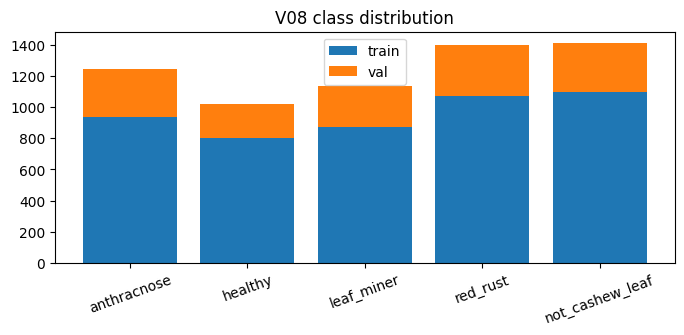

In [16]:
if RUN_MODE == 'FULL':
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.bar(CLASS_NAMES, EXPECTED['train'], label='train')
    ax.bar(CLASS_NAMES, EXPECTED['val'], bottom=EXPECTED['train'], label='val')
    ax.legend(); ax.set_title('V08 class distribution'); plt.xticks(rotation=20); plt.show()


## 05 CBAM and Student-t CI unit checks

In [17]:
from scripts.cbam_v08.smoke_tests import run as run_unit_smoke
from scripts.cbam_v08.cbam_layers import CBAM
from scripts.cbam_v08.statistics_ci import mean_sd_ci95, paired_ci95
SMOKE_RESULT = run_unit_smoke()
print(SMOKE_RESULT)


{'status': 'PASS', 'scope': 'SYNTHETIC UNIT TEST', 'checks': ['Student-t CI', 'paired seed IDs', 'CBAM shapes', 'finite gradients', '.keras reload']}


## 06 Model builders, trainability and source recipe

In [18]:
from scripts.cbam_v08 import model_resnet50, model_densenet121, model_deit_tiny
MODULE = {'resnet50': model_resnet50, 'densenet121': model_densenet121,
          'deit_tiny': model_deit_tiny}[MODEL_KIND]
print(json.dumps(MODULE.RECIPE, indent=2))
print('Paired variants: baseline_no_cbam, cbam')


{
  "stage1": {
    "lr": 0.0003,
    "epochs": 12,
    "early_patience": 4,
    "reduce_patience": 2,
    "min_lr": 1e-06
  },
  "stage2": {
    "lr": 1e-05,
    "epochs": 30,
    "early_patience": 8,
    "reduce_patience": 4,
    "min_lr": 1e-07
  }
}
Paired variants: baseline_no_cbam, cbam


## 07 Source parity and model smoke

Offline smoke builds a random-weight backbone to verify topology, CNN preprocessing, stage trainability and `.keras` reload. This does **not** verify the pretrained checkpoint or full source parity. FULL mode loads the actual ImageNet preset; if it is unavailable, stop with `BLOCKED_BY_SOURCE`. CNN GAP is explicit so CBAM precedes pooling.

In [19]:
if RUN_MODE == 'SMOKE':
    from scripts.cbam_v08.smoke_tests import run_model
    print(run_model(MODEL_KIND))


## 08–09 Paired Stage 1 and Stage 2 — FULL only

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.4749 - loss: 1.3542 - val_accuracy: 0.8063 - val_loss: 0.6294 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.7313 - loss: 0.7315 - val_accuracy: 0.8867 - val_loss: 0.4045 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8234 - loss: 0.5348 - val_accuracy: 0.9042 - val_loss: 0.3219 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8491 - loss: 0.4503 - val_accuracy: 0.9182 - val_loss: 0.2812 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8616 - loss: 0.4021 - val_accuracy: 0.9238 - val_loss: 0.2567 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8850 - loss: 0.3539 - val_accuracy: 0.9175 - val_loss: 0.2463 - learning_rate: 3.0000e-04
Epoch 

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 70 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7244 - loss: 0.7893 - val_accuracy: 0.9070 - val_loss: 0.3006 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9015 - loss: 0.3042 - val_accuracy: 0.9154 - val_loss: 0.2408 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9217 - loss: 0.2381 - val_accuracy: 0.9175 - val_loss: 0.2304 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9357 - loss: 0.2007 - val_accuracy: 0.9301 - val_loss: 0.2041 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9449 - loss: 0.1698 - val_accuracy: 0.9406 - val_loss: 0.1821 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9407 - loss: 0.1644 - val_accuracy: 0.9378 - val_loss: 0.1767 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - ac

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 82 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


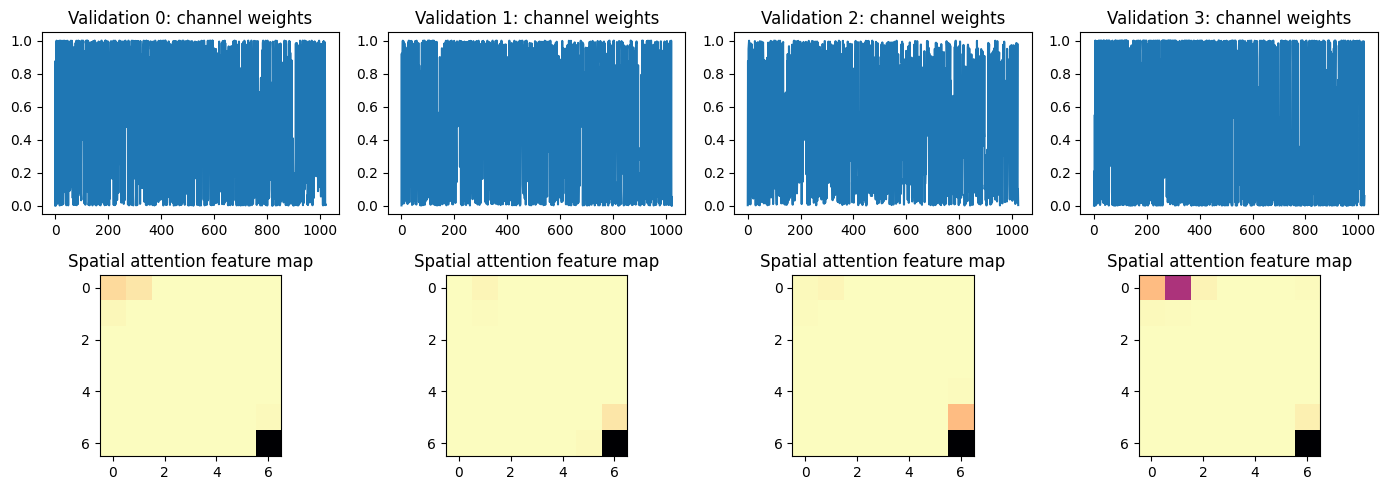

Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.4992 - loss: 1.2598 - val_accuracy: 0.8343 - val_loss: 0.5977 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7620 - loss: 0.6798 - val_accuracy: 0.9007 - val_loss: 0.3852 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8269 - loss: 0.5086 - val_accuracy: 0.9147 - val_loss: 0.3087 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8624 - loss: 0.4270 - val_accuracy: 0.9189 - val_loss: 0.2808 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8691 - loss: 0.3911 - val_accuracy: 0.9245 - val_loss: 0.2463 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8854 - loss: 0.3519 - val_accuracy: 0.9273 - val_loss: 0.2377 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - ac

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 70 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.7432 - loss: 0.7364 - val_accuracy: 0.9252 - val_loss: 0.2805 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9061 - loss: 0.3082 - val_accuracy: 0.9238 - val_loss: 0.2254 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9144 - loss: 0.2449 - val_accuracy: 0.9406 - val_loss: 0.1964 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9271 - loss: 0.2078 - val_accuracy: 0.9315 - val_loss: 0.1913 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9351 - loss: 0.1827 - val_accuracy: 0.9392 - val_loss: 0.1865 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9428 - loss: 0.1706 - val_accuracy: 0.9287 - val_loss: 0.1988 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - ac

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 82 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.4735 - loss: 1.3362 - val_accuracy: 0.8182 - val_loss: 0.6418 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7449 - loss: 0.6981 - val_accuracy: 0.8643 - val_loss: 0.4280 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8223 - loss: 0.5248 - val_accuracy: 0.9168 - val_loss: 0.3126 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8603 - loss: 0.4358 - val_accuracy: 0.9245 - val_loss: 0.2810 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8772 - loss: 0.3871 - val_accuracy: 0.9238 - val_loss: 0.2560 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8806 - loss: 0.3586 - val_accuracy: 0.9287 - val_loss: 0.2388 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - ac

...

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 82 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.5086 - loss: 1.2568 - val_accuracy: 0.8301 - val_loss: 0.5825 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7509 - loss: 0.6888 - val_accuracy: 0.8860 - val_loss: 0.3903 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8322 - loss: 0.5079 - val_accuracy: 0.9168 - val_loss: 0.3013 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8566 - loss: 0.4356 - val_accuracy: 0.9273 - val_loss: 0.2644 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8716 - loss: 0.3905 - val_accuracy: 0.9308 - val_loss: 0.2415 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8683 - loss: 0.3675 - val_accuracy: 0.9364 - val_loss: 0.2311 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - ac

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 70 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Epoch 1/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7317 - loss: 0.7610 - val_accuracy: 0.9028 - val_loss: 0.2781 - learning_rate: 3.0000e-04
Epoch 2/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9088 - loss: 0.2869 - val_accuracy: 0.8867 - val_loss: 0.2959 - learning_rate: 3.0000e-04
Epoch 3/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9228 - loss: 0.2307 - val_accuracy: 0.9329 - val_loss: 0.1984 - learning_rate: 3.0000e-04
Epoch 4/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9357 - loss: 0.1920 - val_accuracy: 0.9238 - val_loss: 0.2093 - learning_rate: 3.0000e-04
Epoch 5/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9415 - loss: 0.1766 - val_accuracy: 0.9434 - val_loss: 0.1905 - learning_rate: 3.0000e-04
Epoch 6/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9436 - loss: 0.1650 - val_accuracy: 0.9357 - val_loss: 0.1871 - learning_rate: 3.0000e-04
Epoch 7/12
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - ac

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 82 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [20]:
if RUN_TRAINING:
    from scripts.cbam_v08.training import run_seed
    from scripts.cbam_v08.reproducibility import environment
    from scripts.cbam_v08.dataset_v08 import sha256
    if not RUN_BASELINE_PAIR or not USE_CBAM or SEEDS != [42, 123, 2026, 3407, 7777] or CI_LEVEL != .95:
        raise ValueError('Primary paired five-seed protocol is locked')
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / 'selection').mkdir(exist_ok=True)
    lock = OUT / 'selection' / 'validation_selection_lock.json'
    rule = {'split': 'val', 'stage_checkpoint': 'minimum val_loss',
            'paired_seeds': SEEDS, 'guardrail': 'RESEARCH_ONLY / NO_DEPLOYMENT_DECISION'}
    if lock.exists() and json.loads(lock.read_text()) != rule:
        raise RuntimeError('Selection rule was already locked with different values')
    lock.write_text(json.dumps(rule, indent=2), encoding='utf-8')
    (OUT / 'dataset_audit.json').write_text(json.dumps(audit, indent=2), encoding='utf-8')
    (OUT / 'environment.json').write_text(json.dumps(environment(), indent=2), encoding='utf-8')
    (OUT / 'experiment_config.json').write_text(json.dumps({'id': EXPERIMENT_ID,
        'model_kind': MODEL_KIND, 'seeds': SEEDS, 'recipe': MODULE.RECIPE,
        'classes': CLASS_NAMES, 'dataset_sha256': ARCHIVE_SHA256,
        'pretrained_source': getattr(MODULE, 'PRESET', f'keras.applications.{MODEL_KIND}:imagenet'),
        'variants': ['baseline_no_cbam', 'cbam'], 'test_enabled': False}, indent=2), encoding='utf-8')
    (OUT / 'baseline_source_snapshot.json').write_text(json.dumps({'historical_experiment':
        HISTORICAL_EXPERIMENT, 'source_notebook': SOURCE_NOTEBOOK,
        'source_sha256': sha256(root / SOURCE_NOTEBOOK) if (root / SOURCE_NOTEBOOK).is_file()
        else SOURCE_SHA256, 'runtime_bundle_sha256': SOURCE_BUNDLE_SHA256}, indent=2), encoding='utf-8')
    (OUT / 'CONFIG_DIFF.md').write_text('# Paired comparison\n\nWithin this notebook the primary '
        'variant differs only by CBAM enabled/disabled. DeiT fusion baseline is new and '
        'historical EXP-007 A is reference only.\n', encoding='utf-8')
    (OUT / 'gate_status.json').write_text(json.dumps({'final_test': 'CLOSED',
        'historical_holdout': 'CLOSED', 'deployment_decision': 'RESEARCH_ONLY'}, indent=2), encoding='utf-8')
    (OUT / 'README.md').write_text(f'# {EXPERIMENT_ID}\n\nPaired five-seed Validation-only '
        'baseline versus CBAM. See experiment_config.json and aggregate/ after completion.\n', encoding='utf-8')
    revision = subprocess.run(['git', '-c', f'safe.directory={root.as_posix()}',
        '-C', str(root), 'rev-parse', 'HEAD'],
        capture_output=True, text=True)
    (OUT / 'source_git_commit.txt').write_text(revision.stdout.strip() or 'UNKNOWN', encoding='utf-8')
    for seed in SEEDS:
        train_ds = dataset(train_paths, train_labels, seed, True, BATCH_SIZE)
        val_ds = dataset(val_paths, val_labels, seed, False, BATCH_SIZE)
        for use_cbam in (False, True):
            run_seed(MODEL_KIND, seed, use_cbam, train_ds, val_ds,
                     val_labels, val_relatives, OUT)


## 10 Validation — only the 1,430 fixed images

Each completed seed writes predictions, per-class metrics, D2H, confusion matrix and checkpoint provenance. No Test or Holdout dataloader exists.

In [21]:
if RUN_MODE in ('FULL', 'VIEW_ONLY'):
    for variant in ('baseline_no_cbam', 'cbam'):
        for seed in SEEDS:
            path = OUT / variant / f'seed_{seed}' / 'validation_metrics.json'
            if path.exists():
                data = json.loads(path.read_text())
                print(variant, seed, 'accuracy', data['accuracy'], 'macro_f1', data['macro_f1'],
                      'D2H', data['disease_to_healthy_count'])


baseline_no_cbam 42 accuracy 0.972027972027972 macro_f1 0.9706063750972967 D2H 9
baseline_no_cbam 123 accuracy 0.9699300699300699 macro_f1 0.9683305996067458 D2H 13
baseline_no_cbam 2026 accuracy 0.972027972027972 macro_f1 0.9708464617419983 D2H 9
baseline_no_cbam 3407 accuracy 0.9699300699300699 macro_f1 0.9683343336198413 D2H 9
baseline_no_cbam 7777 accuracy 0.9699300699300699 macro_f1 0.9683996815971281 D2H 8
cbam 42 accuracy 0.9622377622377623 macro_f1 0.9601316517468244 D2H 15
cbam 123 accuracy 0.9524475524475524 macro_f1 0.9493820101954725 D2H 16
cbam 2026 accuracy 0.9601398601398602 macro_f1 0.9575247556402153 D2H 12
cbam 3407 accuracy 0.9531468531468531 macro_f1 0.9502602787177311 D2H 14
cbam 7777 accuracy 0.9622377622377623 macro_f1 0.9600402898794416 D2H 12


## 11–14 Five-seed aggregate, paired CI, figures and reports

The next cell requires all 10 completed runs; it never invents partial results. Charts display five dots plus CI or sample SD separately.
Learning curves use cumulative epochs. The dotted boundary marks Stage 2, which resumes the best Stage 1 checkpoint; the traces are intentionally separate.


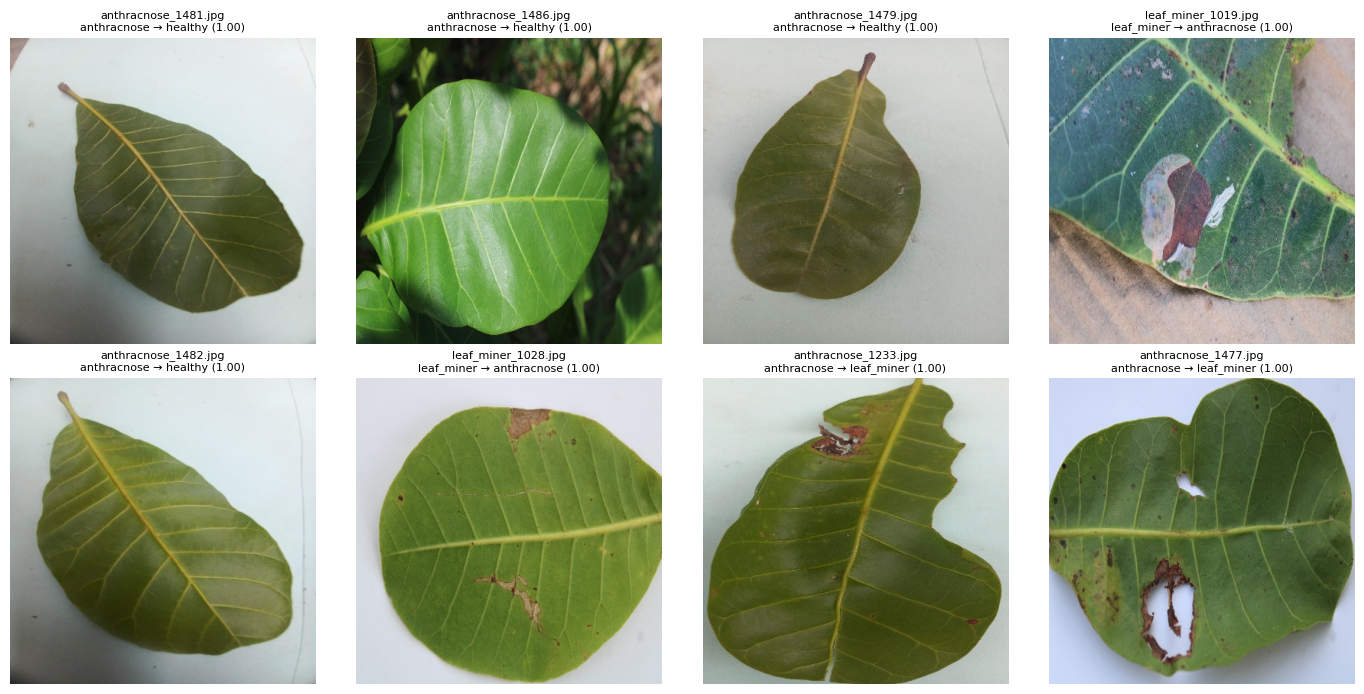

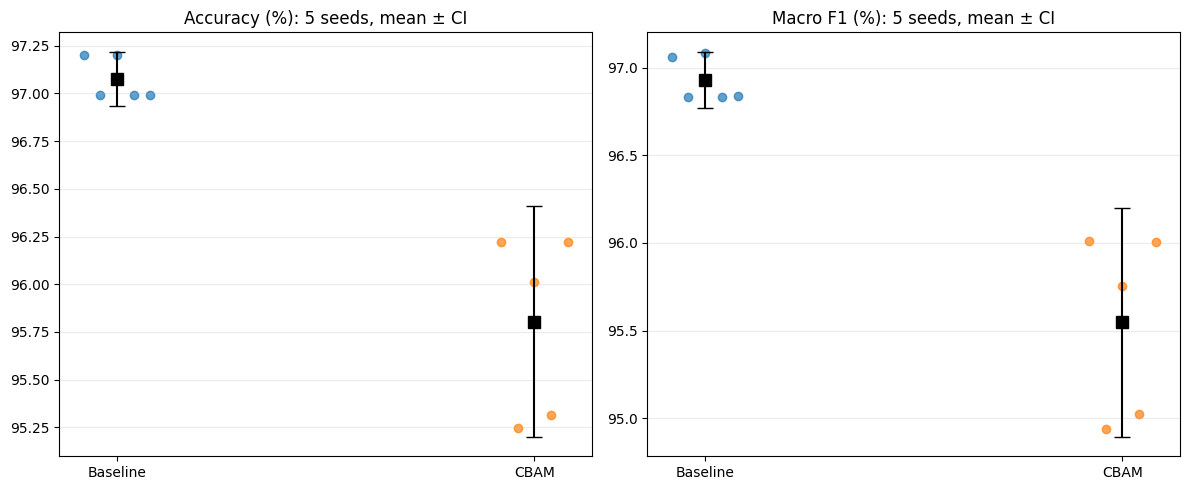

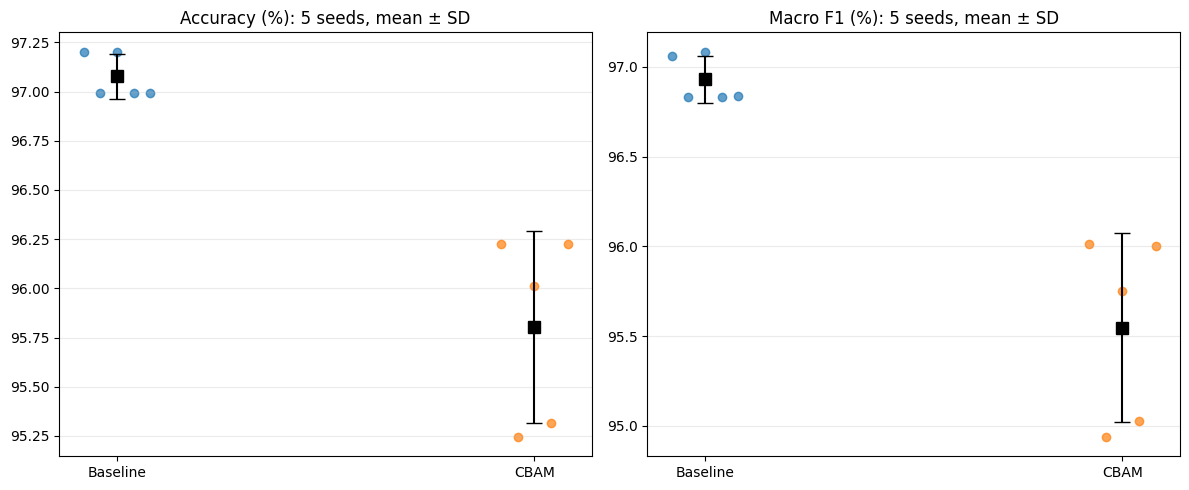

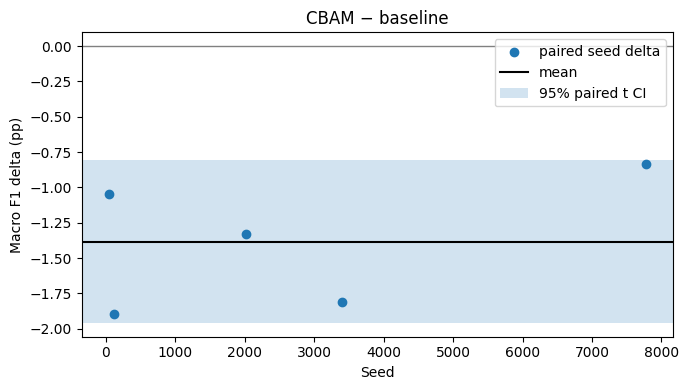

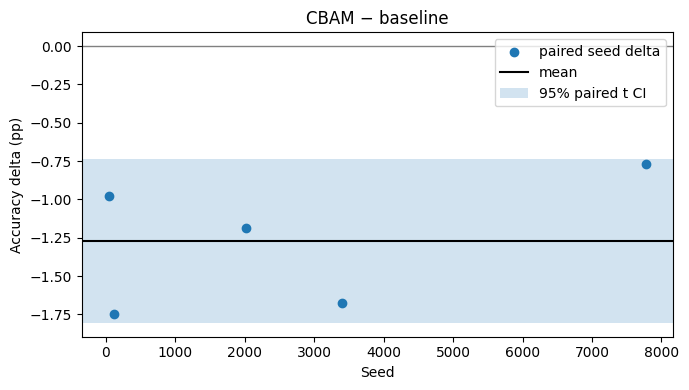

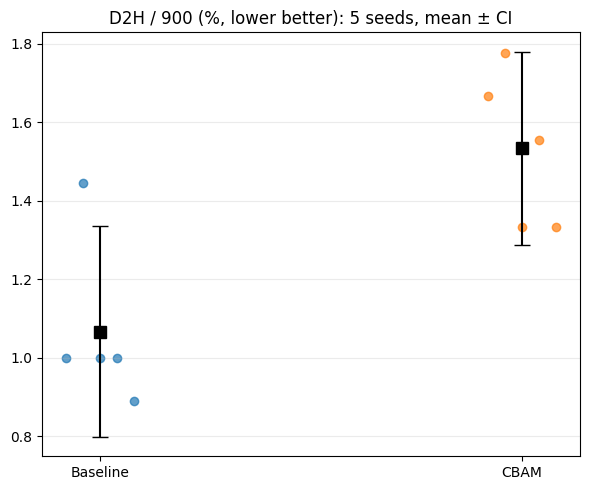

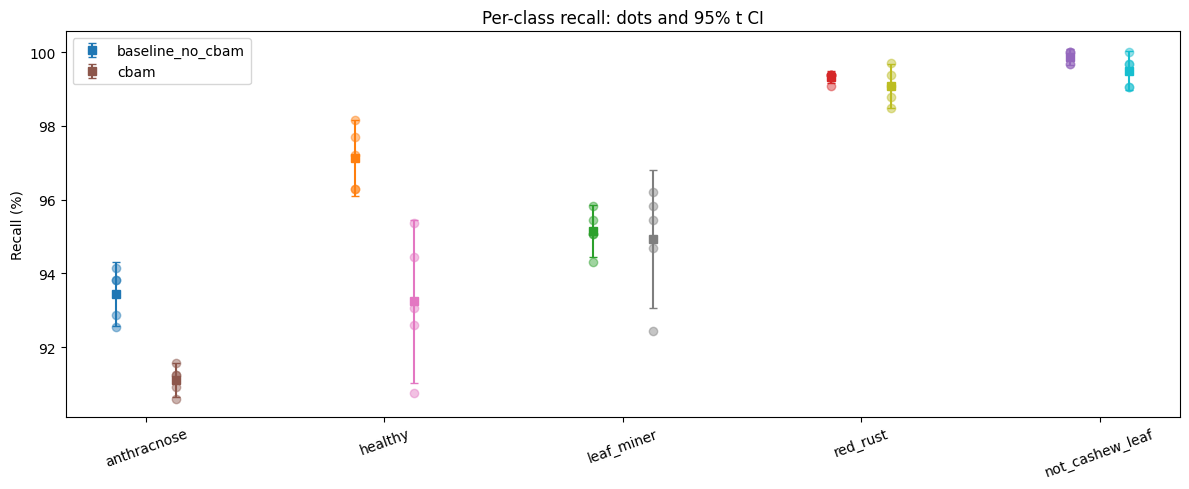

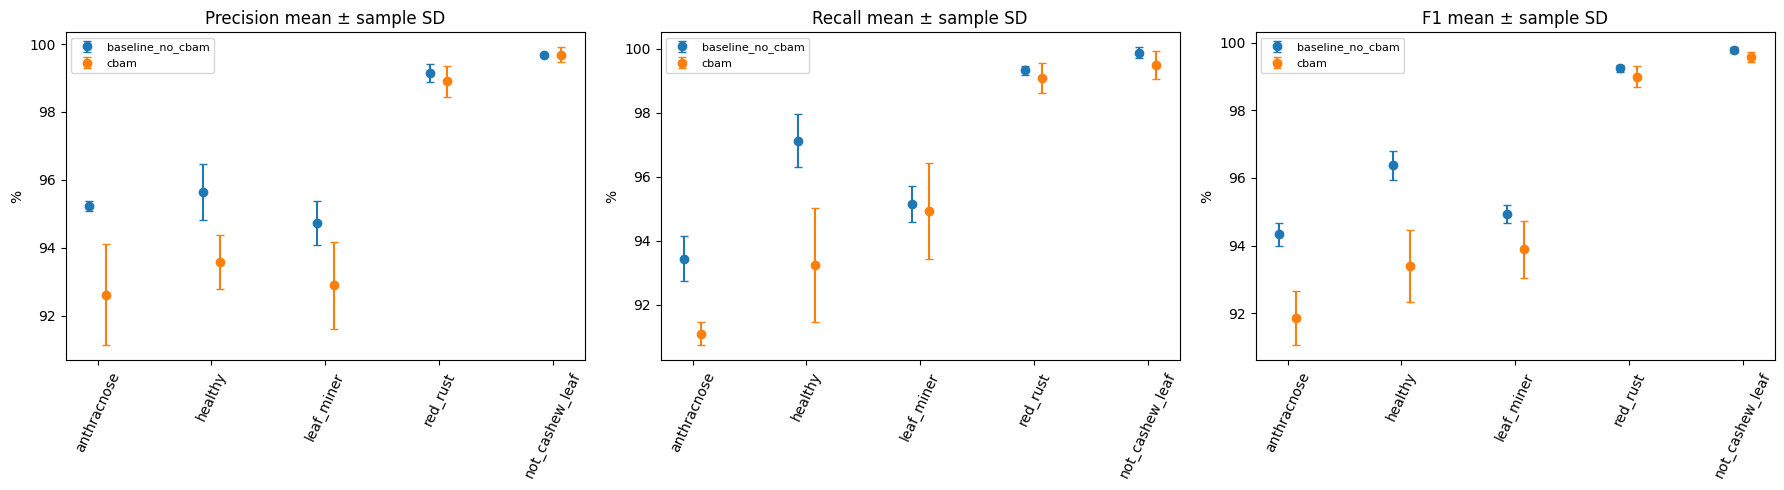

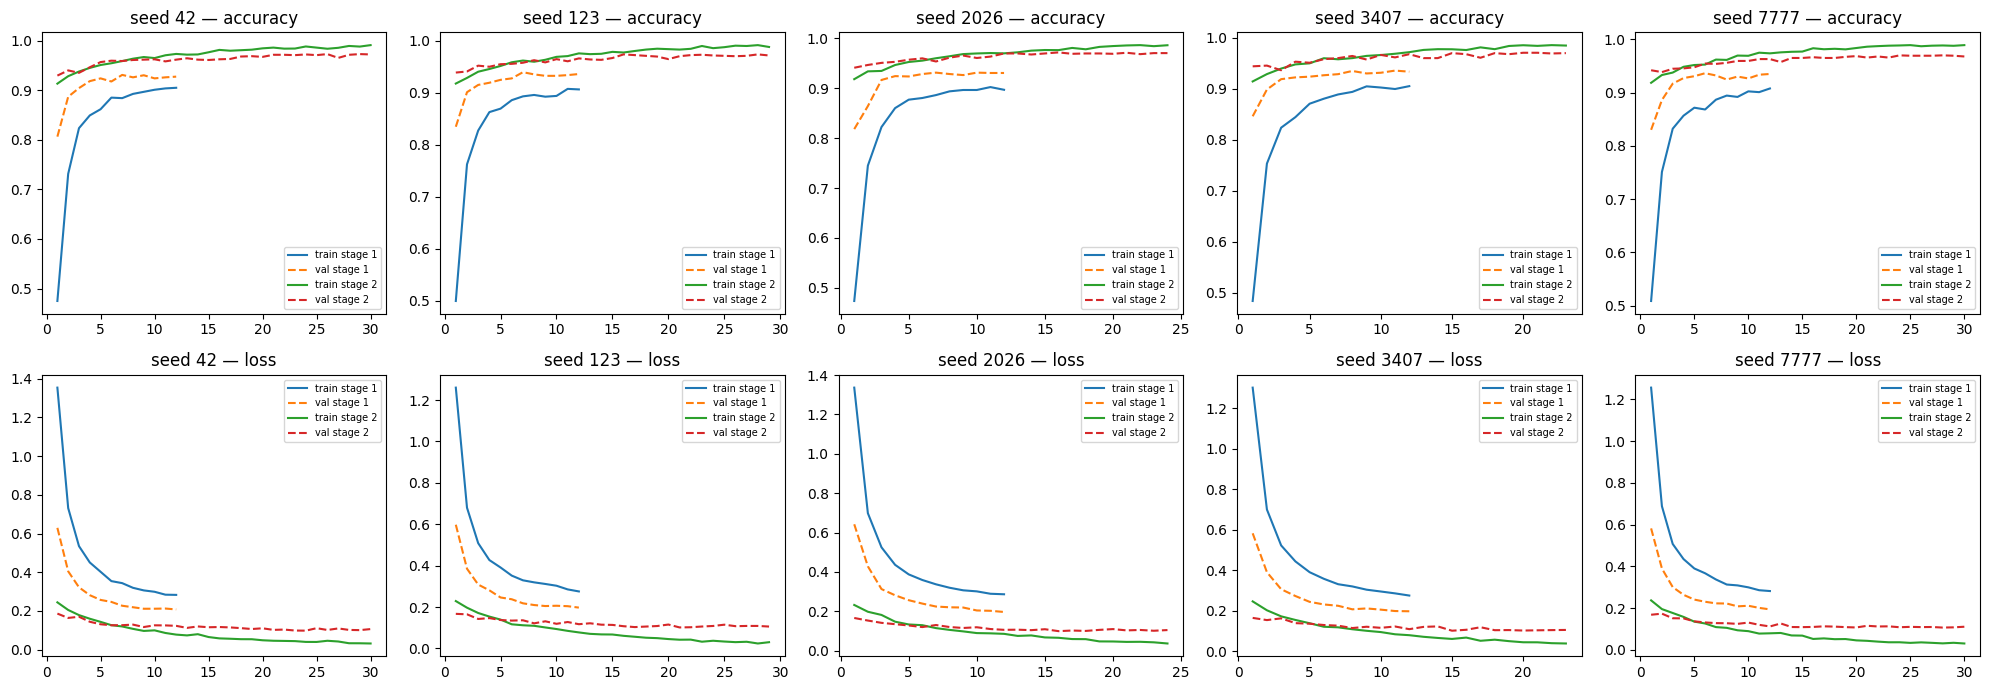

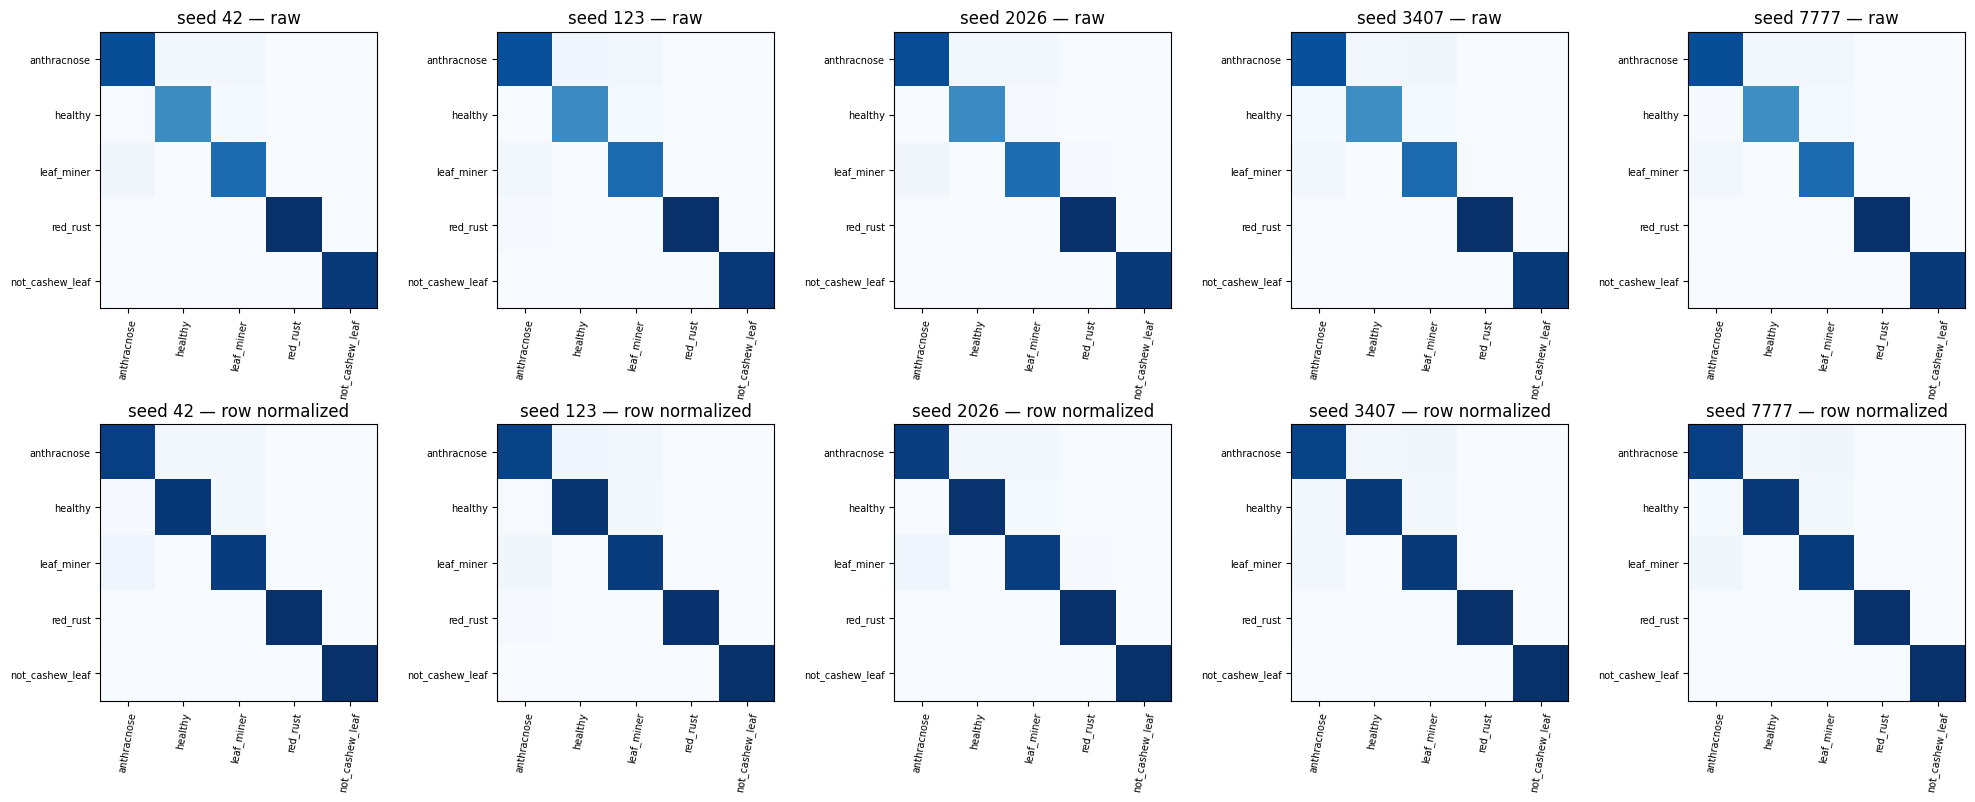

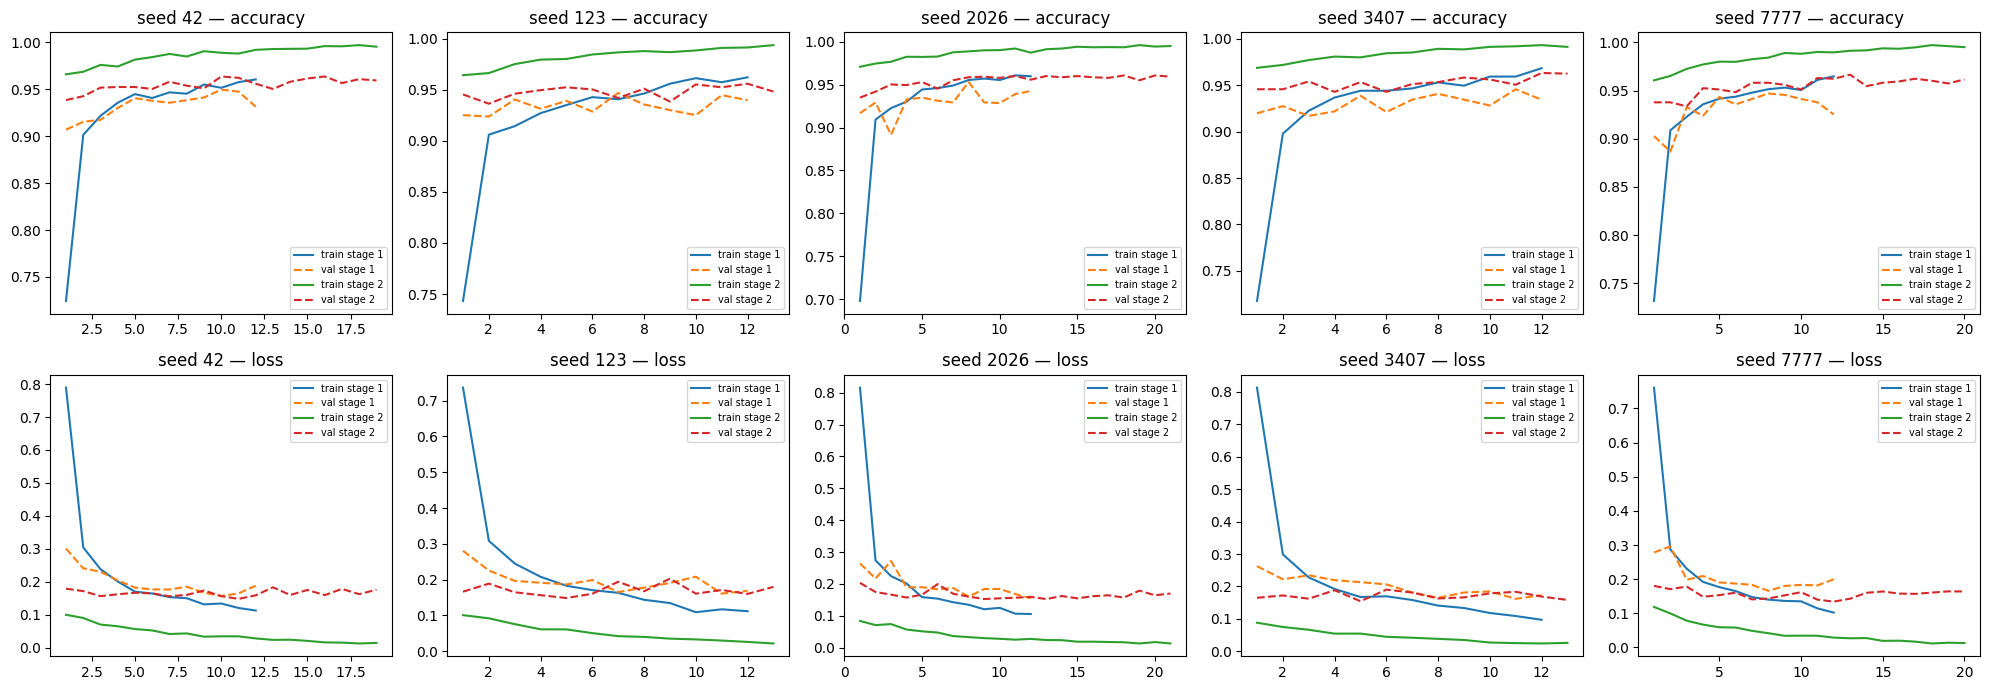

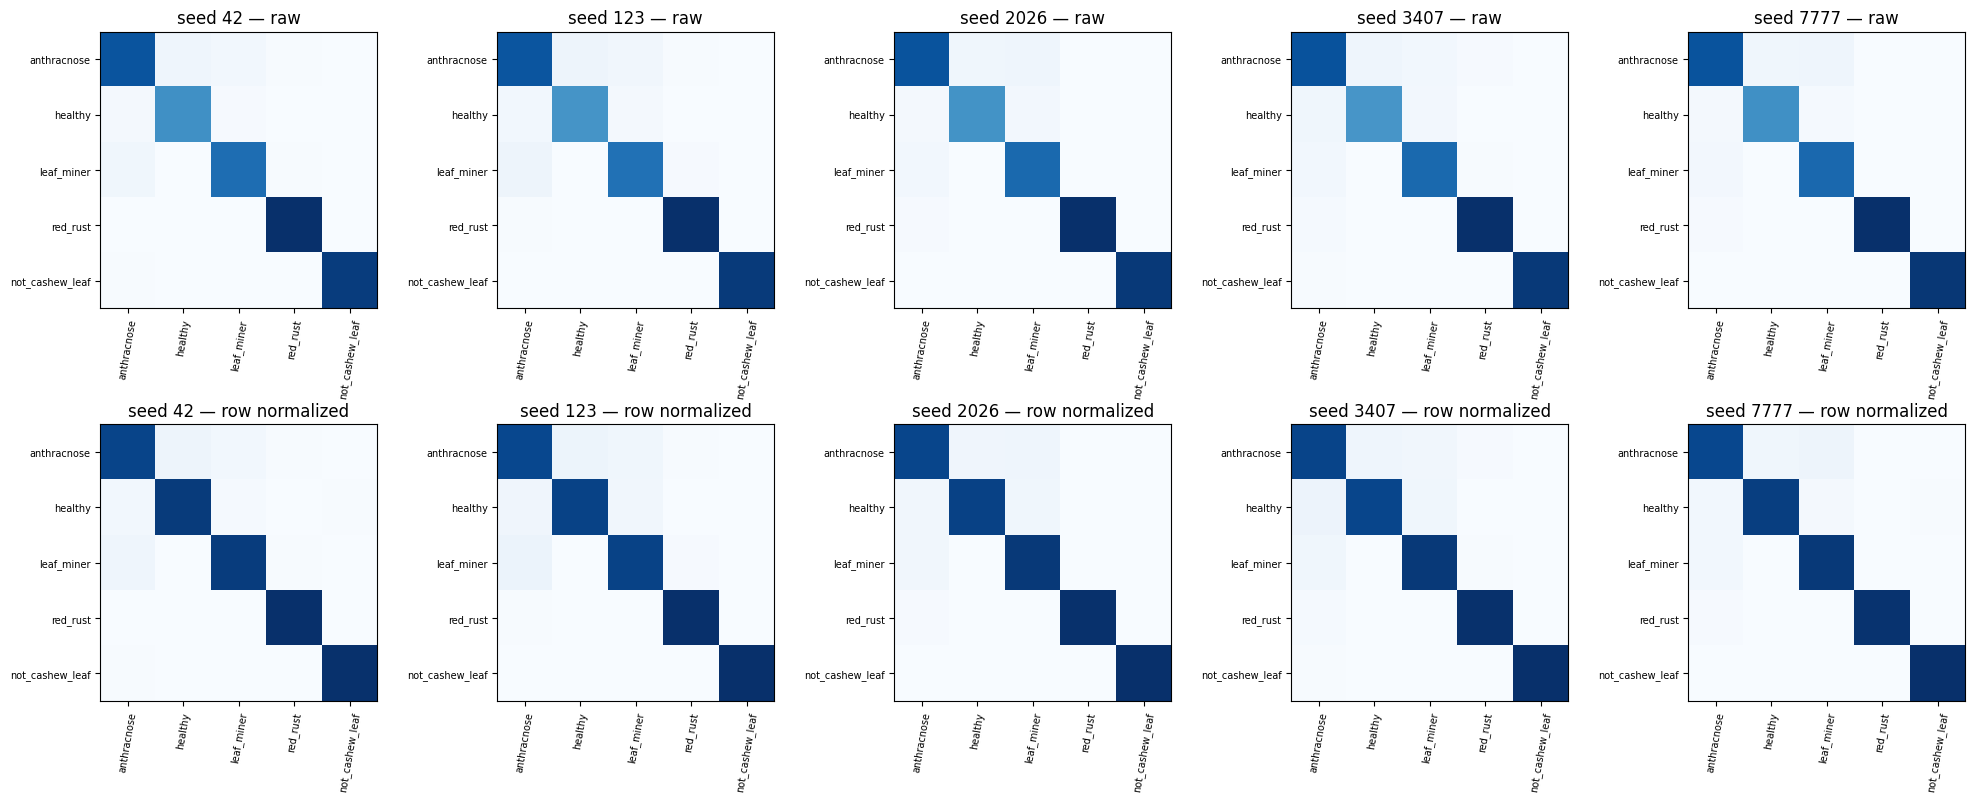

Figures: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-CBAM-TRANSFER-5SEEDS-017/figures CSV: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-CBAM-TRANSFER-5SEEDS-017/aggregate Package: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-CBAM-TRANSFER-5SEEDS-017/packages


In [22]:
if RUN_MODE in ('FULL', 'VIEW_ONLY'):
    if RUN_MODE == 'FULL':
        from scripts.cbam_v08.plots import plot_validation_examples
        plot_validation_examples(OUT, DATA_ROOT)
    from scripts.cbam_v08.aggregate import aggregate
    aggregate(OUT)
    print('Figures:', OUT / 'figures', 'CSV:', OUT / 'aggregate',
          'Package:', OUT / 'packages')
else:
    print('SMOKE only: no experimental metrics or figures created.')


## 15 Final Test and historical Holdout gate

Disabled by policy. Selection and research reporting use Validation only. This notebook has no Test prediction/evaluation cell.

In [23]:
assert RUN_FINAL_TEST is False and RUN_HISTORICAL_HOLDOUT is False
print('Test and historical Holdout gates: CLOSED')


Test and historical Holdout gates: CLOSED


## 16 Manual inference and artifact notes

Open `VIEW_ONLY` after the user completes all paired seeds. Read actual `predictions_val.csv` and the checkpoint hash for any manual Validation review. Checkpoints remain outside the small ANALYSIS package.

In [24]:
if RUN_MODE == 'VIEW_ONLY':
    print('Completed paired results:', OUT / 'aggregate' / 'validation_paired_seed_metrics.csv')
